# 02 · Pipeline: de MASTER a FS (variables reutilizables)

**Objetivo de este cuaderno:** describir a cada cliente con **números** que un modelo pueda usar (cuánto compra, cada cuánto, hace cuánto que no compra…),
calculados **en varias fechas de corte**. Esos números se llaman **variables** (en inglés, *features*).

**¿Qué es FS?** Las siglas vienen de *feature store*, «almacén de variables»: un lugar donde las variables se calculan **una vez**, se documentan
y se reutilizan en cualquier modelo. Aquí es una capa didáctica (dos tablas en SQLite), no una plataforma completa, pero sigue las mismas reglas.

**La fecha de corte.** Un modelo de este tipo se usará así: *«hoy es 1 de septiembre; con lo que sé de cada cliente hasta hoy, ¿quién volverá?»*.
Para entrenarlo, hacemos **fotos del pasado**: para cada fecha de corte calculamos las variables con **lo que se sabía ese día**, y nada más.

```
            pasado: se usa para las VARIABLES                 futuro: solo para el OBJETIVO (cuaderno 03)
  ─────────────────────────────────────────────────┤ corte ├───────────────────────────────►
  compras del cliente:   x      x   x         x     │         x?   ← ¿compra en los 90 días siguientes?
```

> **Regla de oro:** cada variable se calcula **solo con datos anteriores al corte**. Si una variable «mirara» el futuro, el modelo aprendería
> algo que en la vida real no sabrá nunca. Eso se llama **fuga de información** (*data leakage*): da métricas espectaculares en el cuaderno
> y un modelo inútil en producción.

Ejemplo de fuga: calcular `frecuencia` con **todas** las facturas del cliente, también las posteriores al corte. Un cliente que compró en la ventana
tendría más frecuencia justo *porque* compró: el modelo «adivinaría» mirando la respuesta.

**Cuidado con las fugas sutiles.** No basta con filtrar las facturas: también hay que vigilar las **tablas resumen**. `master_clientes.pais` es el país
más frecuente del cliente en **toda** su historia, futuro incluido. Si FS lo usara para `es_reino_unido`, un cliente que se mudara después del corte
cambiaría el pasado. Por eso `sql/fs/02_poblar_fs.sql` recalcula el país **con las facturas anteriores al corte**, y la prueba de fuga borra
`master_clientes` además del futuro: si FS dependiera de ella, la prueba fallaría.

**Entra:** MASTER (cuaderno 01). **Sale:** `fs_catalogo` y `fs_cliente_corte` en `curso.db`, y la figura `reports/figures/fs_distribuciones.png`.

In [1]:
# Parámetros. None usa las rutas por defecto del proyecto (o las variables de entorno CURSO_DB y CURSO_REPORTES).
RUTA_DB = None
RUTA_REPORTES = None
CORTES = {
    'train': ['2010-06-01', '2010-07-01', '2010-08-01', '2010-09-01', '2010-10-01', '2010-11-01', '2010-12-01'],
    'valid': ['2011-03-01'],
    'test': ['2011-06-01', '2011-09-01'],
}

In [2]:
import os, sqlite3, sys
from pathlib import Path

import pandas as pd

pd.set_option('display.width', 150, 'display.max_columns', 30)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml».
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
SQL = RAIZ / 'sql'
DB = Path(RUTA_DB or os.environ.get('CURSO_DB') or RAIZ / 'data' / 'processed' / 'curso.db')
DB.parent.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(DB)
con.execute('PRAGMA foreign_keys = ON')


def ejecutar_script(archivo):
    """Ejecuta un archivo .sql de la carpeta sql/ (puede tener varias sentencias)."""
    con.executescript((SQL / archivo).read_text(encoding='utf-8'))
    con.commit()


def escalar(consulta, parametros=None):
    fila = con.execute(consulta, parametros or {}).fetchone()
    return None if fila is None else fila[0]


print('Proyecto:', RAIZ)
print('Base de datos:', DB)
REPORTES = Path(RUTA_REPORTES or os.environ.get('CURSO_REPORTES') or RAIZ / 'reports')
(REPORTES / 'figures').mkdir(parents=True, exist_ok=True)

Proyecto: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base
Base de datos: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base\data\processed\curso.db


## 1. El catálogo de variables y la tabla destino
`sql/fs/01_crear_fs.sql` crea dos tablas:
- **`fs_catalogo`**: la **documentación** de cada variable (nombre, descripción, fórmula y unidad). Una variable sin documentar no se puede revisar ni reutilizar.
- **`fs_cliente_corte`**: los valores. **Granularidad** (qué representa cada fila): un cliente en una fecha de corte. Su clave es `(cliente_id, fecha_corte)`.

In [3]:
ejecutar_script('fs/01_crear_fs.sql')
pd.read_sql('SELECT feature, descripcion, formula, unidad FROM fs_catalogo', con)

,feature,descripcion,formula,unidad
0,recencia_dias,Dias desde la ultima compra valida hasta el corte,corte - max(fecha_factura),dias
1,frecuencia,Numero de facturas con ventas validas antes de...,count(distinct factura),facturas
2,monto_total,Gasto acumulado en ventas validas antes del corte,sum(monto_linea),GBP
3,ticket_medio,Gasto medio por factura,monto_total / frecuencia,GBP
4,unidades_total,Unidades compradas antes del corte,sum(cantidad),unidades
5,productos_distintos,Productos distintos comprados antes del corte,count(distinct codigo_producto),productos
6,antiguedad_dias,Dias desde la primera compra valida hasta el c...,corte - min(fecha_factura),dias
7,frecuencia_90d,Facturas en los 90 dias previos al corte,count(factura) con fecha >= corte - 90 dias,facturas
8,monto_90d,Gasto en los 90 dias previos al corte,sum(monto) con fecha >= corte - 90 dias,GBP
9,frecuencia_180d,Facturas en los 180 dias previos al corte,count(factura) con fecha >= corte - 180 dias,facturas


## 2. Poblar FS: una vez por fecha de corte
`sql/fs/02_poblar_fs.sql` es **una sola sentencia** con el parámetro `:corte`. Se ejecuta una vez por cada fecha de corte, cambiando solo ese valor.
**Léela:** todos sus filtros dicen `fecha_factura < :corte`. Esa condición es la que garantiza la regla de oro.

**¿Por qué varios cortes?** Cada corte es una foto distinta del mismo cliente. Con muchas fotos el modelo ve más ejemplos y momentos diferentes
(antes y después de Navidad, por ejemplo). Los cortes de cada partición (train, valid, test) se fijan en la celda de parámetros.

Las variables solo usan **ventas válidas** (`es_venta_valida = 1`), salvo `devoluciones`. En cada corte solo aparecen los clientes con
**al menos una compra válida antes del corte**: de un cliente que aún no ha comprado no hay nada que describir. Casi todas siguen la idea clásica **RFM** del marketing:
**R**ecencia (hace cuánto compró), **F**recuencia (cuántas veces) y **M**onto (cuánto gastó).

| Variable | Qué mide | Intuición |
|---|---|---|
| `recencia_dias` | Días desde la última compra hasta el corte | Quien compró hace poco suele volver |
| `frecuencia` | Facturas con ventas válidas | Quien compra a menudo, repite |
| `monto_total`, `ticket_medio` | Gasto acumulado y gasto medio por factura | Valor del cliente |
| `unidades_total`, `productos_distintos` | Volumen y variedad | ¿Mayorista o comprador puntual? |
| `antiguedad_dias` | Días desde la primera compra | Clientes nuevos frente a veteranos |
| `frecuencia_90d`, `monto_90d`, `frecuencia_180d` | Actividad en los últimos 90 y 180 días | La tendencia reciente pesa más |
| `dias_medios_entre_compras` | Ritmo de compra (nulo si solo hay una) | ¿Compra cada mes o cada año? |
| `devoluciones` | Facturas de cancelación | Señal de insatisfacción |
| `es_reino_unido` | 1 si el país más frecuente de sus compras **antes del corte** es Reino Unido | El mercado local se comporta distinto |

In [4]:
sql_fs = (SQL / 'fs' / '02_poblar_fs.sql').read_text(encoding='utf-8')
todos_los_cortes = [c for lista in CORTES.values() for c in lista]
for corte in todos_los_cortes:
    con.execute(sql_fs, {'corte': corte})
    con.commit()
    print(f'corte {corte}: {escalar("SELECT COUNT(*) FROM fs_cliente_corte WHERE fecha_corte = :c", {"c": corte}):,} clientes')

corte 2010-06-01: 69 clientes
corte 2010-07-01: 80 clientes
corte 2010-08-01: 84 clientes
corte 2010-09-01: 88 clientes


corte 2010-10-01: 93 clientes
corte 2010-11-01: 103 clientes
corte 2010-12-01: 109 clientes
corte 2011-03-01: 114 clientes


corte 2011-06-01: 119 clientes
corte 2011-09-01: 131 clientes


In [5]:
pd.read_sql('SELECT * FROM fs_cliente_corte ORDER BY fecha_corte, cliente_id LIMIT 6', con)

,cliente_id,fecha_corte,recencia_dias,frecuencia,monto_total,ticket_medio,unidades_total,productos_distintos,antiguedad_dias,frecuencia_90d,monto_90d,frecuencia_180d,dias_medios_entre_compras,devoluciones,es_reino_unido
0,12369,2010-06-01,84,1,308.32,308.32,208,8,84,1,308.32,1,NaN,0,0
1,12503,2010-06-01,27,1,896.00,896.00,560,1,27,1,896.00,1,NaN,0,0
2,12523,2010-06-01,25,5,1179.47,235.89,739,62,175,2,621.73,5,37.5,3,0
3,12567,2010-06-01,25,2,799.13,399.57,349,38,109,1,312.85,2,84.0,1,0
4,12665,2010-06-01,112,1,150.80,150.80,74,7,112,0,0.00,1,NaN,1,0
5,12670,2010-06-01,109,1,207.60,207.60,48,7,109,0,0.00,1,NaN,0,0


In [6]:
pd.read_sql('SELECT fecha_corte, COUNT(*) AS clientes, ROUND(AVG(recencia_dias),1) AS recencia_media, ROUND(AVG(frecuencia),1) AS frecuencia_media, ROUND(AVG(monto_total),0) AS monto_medio FROM fs_cliente_corte GROUP BY fecha_corte ORDER BY fecha_corte', con)

,fecha_corte,clientes,recencia_media,frecuencia_media,monto_medio
0,2010-06-01,69,50.8,3.0,1135.0
1,2010-07-01,80,51.8,3.3,1221.0
2,2010-08-01,84,64.8,3.6,1346.0
3,2010-09-01,88,83.1,3.9,1449.0
4,2010-10-01,93,87.9,4.1,1551.0
5,2010-11-01,103,78.0,4.4,1713.0
6,2010-12-01,109,80.4,4.6,1843.0
7,2011-03-01,114,132.1,5.2,2117.0
8,2011-06-01,119,151.7,5.8,2309.0
9,2011-09-01,131,177.5,6.0,2352.0


## 3. Comprobar la regla de oro con un cliente
Un buen hábito: **recalcular a mano** algún resultado con otra herramienta. Aquí recalculamos con pandas la recencia y la frecuencia de un cliente
usando solo lo anterior al corte y comparamos con lo que calculó SQL. Si no coinciden, uno de los dos está mal.
También contamos sus facturas **posteriores** al corte: existen, pero FS no debe haberlas usado.

In [7]:
corte = CORTES['train'][-1]
cliente = int(escalar('SELECT cliente_id FROM fs_cliente_corte WHERE fecha_corte = :c ORDER BY frecuencia DESC LIMIT 1', {'c': corte}))
ventas = pd.read_sql("""
    SELECT f.factura_id, f.fecha_factura FROM master_lineas l JOIN master_facturas f ON f.factura_id = l.factura_id
    WHERE l.es_venta_valida = 1 AND f.cliente_id = :c GROUP BY f.factura_id""", con, params={'c': cliente})
ventas['fecha'] = pd.to_datetime(ventas['fecha_factura'])
antes = ventas[ventas['fecha'] < pd.Timestamp(corte)]
despues = ventas[ventas['fecha'] >= pd.Timestamp(corte)]
fs = pd.read_sql('SELECT recencia_dias, frecuencia FROM fs_cliente_corte WHERE cliente_id = :c AND fecha_corte = :f', con, params={'c': cliente, 'f': corte}).iloc[0]
recencia_a_mano, frecuencia_a_mano = (pd.Timestamp(corte) - antes['fecha'].max()).days, len(antes)
print(f'Cliente {cliente} · corte {corte}')
print('FS dice:       recencia', int(fs.recencia_dias), '| frecuencia', int(fs.frecuencia))
print('A mano:        recencia', recencia_a_mano, '| frecuencia', frecuencia_a_mano)
print('Facturas del cliente DESPUÉS del corte (el modelo NO debe verlas):', len(despues))
assert (int(fs.recencia_dias), int(fs.frecuencia)) == (recencia_a_mano, frecuencia_a_mano)

Cliente 13093 · corte 2010-12-01
FS dice:       recencia 0 | frecuencia 47
A mano:        recencia 0 | frecuencia 47
Facturas del cliente DESPUÉS del corte (el modelo NO debe verlas): 8


## 4. La prueba definitiva contra la fuga
`tests/test_fs_y_ml.py::test_fs_no_usa_informacion_del_futuro` borra **todo** lo posterior a un corte, recalcula FS y comprueba que las variables no cambian.
Ejecútala en una terminal: `pytest tests -k futuro`.

## 5. Mirar las variables
Antes de entrenar, **mira las distribuciones**. Fíjate en que `frecuencia` y `monto_total` son muy **asimétricas**: la mayoría de clientes compra poco
y unos pocos compran muchísimo. Por eso el modelo lineal del cuaderno 04 aplica un **logaritmo** a las variables antes de usarlas: comprime los valores
extremos para que unos pocos clientes no dominen el modelo.

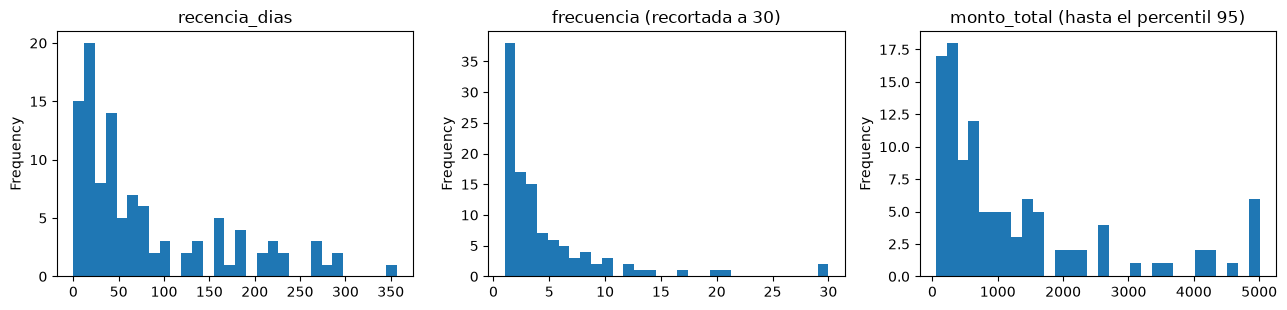

In [8]:
import matplotlib
matplotlib.use('Agg') if os.environ.get('CURSO_SIN_PANTALLA') else None
import matplotlib.pyplot as plt

df = pd.read_sql('SELECT * FROM fs_cliente_corte WHERE fecha_corte = :c', con, params={'c': corte})
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
df['recencia_dias'].plot.hist(bins=30, ax=ax[0], title='recencia_dias')
df['frecuencia'].clip(upper=30).plot.hist(bins=30, ax=ax[1], title='frecuencia (recortada a 30)')
df['monto_total'].clip(upper=df['monto_total'].quantile(0.95)).plot.hist(bins=30, ax=ax[2], title='monto_total (hasta el percentil 95)')
plt.tight_layout()
fig.savefig(REPORTES / 'figures' / 'fs_distribuciones.png', dpi=110)
plt.show()

In [9]:
con.close()
print('Listo: FS construida en', DB)

Listo: FS construida en C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base\data\processed\curso.db


## Resumen
- FS describe a cada cliente en cada fecha de corte con 13 variables documentadas en `fs_catalogo`.
- Todas se calculan **solo con el pasado** (`fecha_factura < :corte`); lo hemos comprobado a mano y lo comprueba una prueba automática.

**Siguiente:** el cuaderno **03** añade a estas variables la respuesta que queremos predecir (`y`) y reparte las filas en train, valid y test.

## Para practicar (tarea de S1)
**Adapta una variable.** Añade una variable nueva a FS, por ejemplo `dias_desde_ultima_cancelacion` o `monto_ultima_factura`:
1. Añade la columna en `sql/fs/01_crear_fs.sql` y su cálculo en `02_poblar_fs.sql`, usando **solo** `fecha_factura < :corte`.
2. Descríbela en `fs_catalogo`.
3. Comprueba con la prueba de «sin información del futuro» que no hay fuga.